# test_master — Memory-safe loading of the 34 GB S1 parquet

Standalone tester for the `sr3_alpha_s1s2_full.parquet` (~34 GB, ~584 M rows).

**Run top to bottom.** Edit the `CONFIG` cell (especially `A_MIN`/`A_MAX`) if the
survivor count / estimated memory is still too large.

| Step | What it does | Peak RAM |
|------|--------------|----------|
| 1 | parquet metadata (footer only) | ~0 |
| 2 | streamed area/width/r2 histograms | ~1 batch |
| 3 | exact row count after the pre-filter | ~1 batch |
| 4 | build reduced parquet (projection + downcast) | ~1 batch |
| 5 | load reduced file + memory report | reduced size |
| 6 | sanity plots (partitions, alpha band) | reduced size |


## 0. Config


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CONFIG — edit here
# ═══════════════════════════════════════════════════════════════
from pathlib import Path
import datetime, time, gc

SRC = "/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_full.parquet"

# Pre-filter = the cuts the master applies anyway (cells 15 / 25 / 26) + the alpha area window.
CUTOFF_DATE = "2026-04-22"          # master cell 15
W_MIN, W_MAX = 40.0, 200.0          # master cell 25   [ns]
R2_MAX       = 3800.0               # master cell 26   [cm^2]  (NaN kept)
A_MIN, A_MAX = 20e3, 120e3          # alpha window [PE]

OUT = "/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_master_reduced.parquet"

# Columns the master pipeline actually needs.
# Position kept once as x/y (x == x_naive, y == y_naive for these S1 peaks);
# dropped: endtime / x_naive / y_naive / r / type — unused downstream.
KEEP_COLS = ["time", "area", "area_fraction_top", "range_50p_area",
             "r2", "x", "y", "run_name"]

CHUNK = 2_000_000                   # rows per streamed batch

cutoff_ns = int(datetime.datetime.strptime(CUTOFF_DATE, "%Y-%m-%d")
                .replace(tzinfo=datetime.timezone.utc).timestamp() * 1e9)

print("source :", SRC)
print("output :", OUT)
print("cutoff :", CUTOFF_DATE)
print("filter : width[%g,%g]  r2<=%g (NaN kept)  area[%g,%g]"
      % (W_MIN, W_MAX, R2_MAX, A_MIN, A_MAX))


## 1. Parquet metadata (reads footer only — no rows loaded)


In [ ]:
import pyarrow.parquet as pq
pf = pq.ParquetFile(SRC)
print("rows      :", f"{pf.metadata.num_rows:,}")
print("row groups:", pf.metadata.num_row_groups)
print("on disk   : %.1f GB" % (Path(SRC).stat().st_size / 1e9))
print()
print(pf.schema_arrow)


## 2. Streaming histograms (peak RAM ≈ one batch)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

edges_a  = np.linspace(0, 1.5e5, 151)
edges_w  = np.linspace(0, 500,   101)
edges_r2 = np.linspace(0, 8e3,    81)
h_a  = np.zeros(len(edges_a)  - 1)
h_w  = np.zeros(len(edges_w)  - 1)
h_r2 = np.zeros(len(edges_r2) - 1)

n_total = 0
for b in pf.iter_batches(columns=["area", "range_50p_area", "r2"], batch_size=CHUNK):
    n_total += b.num_rows
    h_a  += np.histogram(b.column("area").to_numpy(),           bins=edges_a)[0]
    h_w  += np.histogram(b.column("range_50p_area").to_numpy(), bins=edges_w)[0]
    r2 = b.column("r2").to_numpy()
    h_r2 += np.histogram(r2[np.isfinite(r2)], bins=edges_r2)[0]
print("counted rows:", f"{n_total:,}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].step(edges_a[:-1], h_a, where="post", color="k"); ax[0].set_yscale("log")
ax[0].axvline(A_MIN, color="r", ls="--"); ax[0].axvline(A_MAX, color="r", ls="--")
ax[0].set_xlabel("area [PE]"); ax[0].set_ylabel("counts"); ax[0].set_title("Area")
ax[1].step(edges_w[:-1], h_w, where="post", color="k"); ax[1].set_yscale("log")
ax[1].axvline(W_MIN, color="r", ls="--"); ax[1].axvline(W_MAX, color="r", ls="--")
ax[1].set_xlabel("range_50p_area [ns]"); ax[1].set_title("Width")
ax[2].step(edges_r2[:-1], h_r2, where="post", color="k"); ax[2].set_yscale("log")
ax[2].axvline(R2_MAX, color="r", ls="--")
ax[2].set_xlabel("r2 [cm$^2$]"); ax[2].set_title("r2")
plt.tight_layout(); plt.show()


## 3. Exact survivor count after the pre-filter (streamed scan)


In [ ]:
import pyarrow.dataset as ds

dataset = ds.dataset(SRC, format="parquet")
flt = ((ds.field("time") >= cutoff_ns)
       & (ds.field("range_50p_area") >= W_MIN) & (ds.field("range_50p_area") <= W_MAX)
       & (ds.field("area") >= A_MIN) & (ds.field("area") <= A_MAX)
       & ((ds.field("r2") <= R2_MAX) | ds.field("r2").is_null()))

n_keep = dataset.count_rows(filter=flt)
print("rows total     : %15s" % f"{n_total:,}")
print("rows after cut : %15s  (%.1f%% kept)" % (f"{n_keep:,}", 100 * n_keep / n_total))
print("est. memory    : %.2f GB   (float32 + category run_name, ~36 B/row)" % (n_keep * 36 / 1e9))
if n_keep * 36 / 1e9 > 15:
    print(">>> still large — tighten A_MIN in CONFIG and re-run cells 2-3")


## 4. Build reduced parquet (streaming: column projection + downcast)


In [ ]:
import pyarrow as pa

if Path(OUT).exists():
    print("already exists, skipping build:", OUT)
else:
    FLOAT32 = {"area", "area_fraction_top", "range_50p_area", "r2", "x", "y"}
    writer = None
    n_out = 0
    t0 = time.time()
    for batch in dataset.scanner(columns=KEEP_COLS, filter=flt,
                                 batch_size=CHUNK).to_batches():
        cols = []
        for name in KEEP_COLS:
            col = batch.column(name)
            if name in FLOAT32:
                col = col.cast(pa.float32())
            cols.append(col)
        tbl = pa.Table.from_arrays(cols, names=KEEP_COLS)
        if writer is None:
            writer = pq.ParquetWriter(OUT, tbl.schema, compression="snappy")
        writer.write_table(tbl)
        n_out += batch.num_rows
    if writer:
        writer.close()
    print("wrote %s rows -> %s" % (f"{n_out:,}", OUT))
    print("size: %.2f GB   (%.0fs)" % (Path(OUT).stat().st_size / 1e9, time.time() - t0))

gc.collect()


## 5. Load the reduced file (with memory report)


In [ ]:
import pandas as pd

df = pd.read_parquet(OUT, columns=KEEP_COLS)
df["run_name"] = df["run_name"].astype("category")

mem = df.memory_usage(deep=True).sum() / 1e9
print("df shape :", df.shape)
print("dtypes   :")
print(df.dtypes)
print("memory   : %.2f GB" % mem)
if mem > 15:
    print(">>> WARNING: >15 GB — tighten A_MIN, or switch to partition-wise processing")


## 6. Sanity — partitions + alpha band


events per partition:
partition
P1: OLD Q5                        0
P2: ST707, Q5 removed             0
P3: ST707, Q5 Rn cleaned          0
P4: FRESH Q5                 312779
P5: POST 0708               1501312
Name: count, dtype: int64
runs : 1185  (083002 -> 086408)


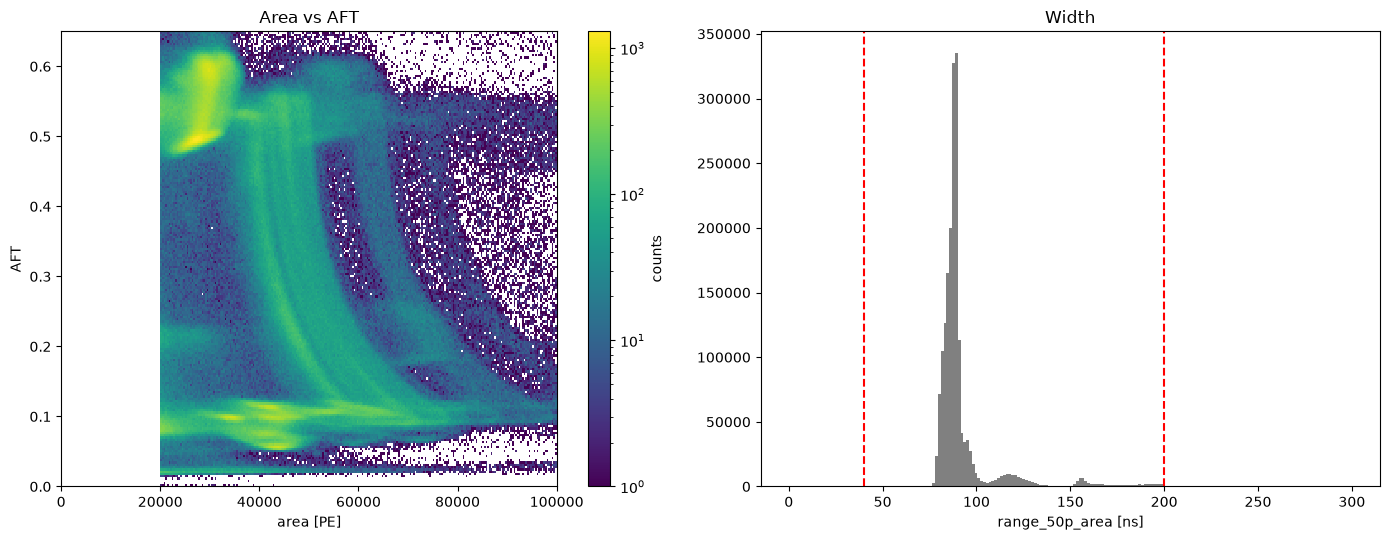

In [18]:
def to_ts(s):
    return pd.Timestamp(s, tz="UTC").timestamp()

PARTITIONS = [
    ("P1: OLD Q5",               to_ts("2026-05-01"), to_ts("2026-05-11")),
    ("P2: ST707, Q5 removed",    to_ts("2026-05-11"), to_ts("2026-05-26")),
    ("P3: ST707, Q5 Rn cleaned", to_ts("2026-05-26"), to_ts("2026-06-12")),
    ("P4: FRESH Q5",             to_ts("2026-06-12"), to_ts("2026-07-08")),
    ("P5: POST 0708",            to_ts("2026-07-08"), to_ts("2026-09-03")),
]
ts = df["time"].to_numpy() / 1e9
labels = [p[0] for p in PARTITIONS]
conds = [(ts >= t0) & (ts < t1) for _, t0, t1 in PARTITIONS]
df["partition"] = pd.Categorical(np.select(conds, labels, default=None), categories=labels)

print("events per partition:")
print(df["partition"].value_counts().sort_index())
print("runs : %d  (%s -> %s)" % (df["run_name"].nunique(),
                                  df["run_name"].astype(str).min(), df["run_name"].astype(str).max()))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
h = ax[0].hist2d(df["area"], df["area_fraction_top"], bins=[300, 200],
                 range=[[0, 100e3], [0, 0.65]], cmin=1,
                 norm=plt.matplotlib.colors.LogNorm(), cmap="viridis")
plt.colorbar(h[3], ax=ax[0], label="counts")
ax[0].set_xlabel("area [PE]"); ax[0].set_ylabel("AFT")
ax[0].set_title("Area vs AFT")
ax[1].hist(df["range_50p_area"], bins=200, range=[0, 300], color="gray")
ax[1].axvline(W_MIN, color="r", ls="--"); ax[1].axvline(W_MAX, color="r", ls="--")
ax[1].set_xlabel("range_50p_area [ns]"); ax[1].set_title("Width")
plt.tight_layout(); plt.show()


## Next — plug `OUT` into the master notebook

In `rn222_analysis_master.ipynb`:

1. **Cell 4** — set the input to the reduced file:
   ```python
   INPUTS = [
       ('/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_master_reduced.parquet', 'S1+S2'),
   ]
   ```
2. **Cell 13** — read parquet instead of pickle:
   ```python
   for path, source in INPUTS:
       d = pd.read_parquet(path, columns=KEEP_COLS_M, dtype=...)
       d['run_name'] = d['run_name'].astype('category')
       d['source'] = source
       frames.append(d)
   ```

Everything else (cuts, 3 corrections, FV, fits, rates, trends) runs unchanged,
because the pre-filter is exactly the set of cuts the master already applies.

> If even the reduced file is too big, tell me and I'll switch this to
> **partition-wise** processing (corr1/2/3 already filter by `partition`),
> which caps peak RAM at a single partition.
